<a href="https://colab.research.google.com/github/chenjeraichantelle-gif/11-17-in-class-assignment/blob/main/DTSC_4050/Assignments/DTSC_4050_Assignment_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DTSC 4050 — Assignment 2
## Probability, Sampling, and Empirical Distributions

**Total: 125 points**

### Instructions
Complete all questions in this notebook. Show calculations where requested, include Python code and output for computational questions, and answer interpretation questions in complete sentences. Use concepts and techniques from the Week 6 and Week 7 activity notebooks.

| Part | Topic | Points |
|---|---|---:|
| 1 | Probability Rules | 10 |
| 2 | Conditional Probability & Dependence | 25 |
| 3 | Sampling Methods | 25 |
| 4 | Theoretical vs. Empirical Distributions | 15 |
| 5 | Population Parameters & Sample Statistics | 25 |
| 6 | Empirical Distribution of a Statistic | 25 |
| **Total** | | **125** |

## Setup
Run this cell before beginning.

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(4050)

# Part 1 — Probability Rules: Colored Cards (10 points)

A box contains **8 cards**: 3 Red, 2 Blue, 2 Green, and 1 Yellow. Assume each card is equally likely to be selected.



### 1.1 — Basic Probabilities (2.5 pts)
Calculate by hand: **P(Red), P(Green), and P(Not Blue)**. Show your calculations.



**Your answer:**
1. red 3/8 = 0.375 = 37.5%
2. Green 2/8 = o.25 = 25%
3. blue 8-2= 6/8 = 0.75 = 75%


### 1.2 — Addition Rule (2.5 pts)
What is the probability of selecting **Red OR Green**? Show your calculation and explain why the probabilities can be added.



- p(A or B) = P(A) + P(B)
3/8 + 2/8 = 5/8 = 0.625= 62,5% IS The probability of red or green . The two events are mutually exclusive so we add.







### 1.3 — Python Verification (5 pts)
Create a NumPy array representing the cards. Simulate **10,000 selections with replacement** using `rng.choice()`. Calculate empirical probabilities for Red, Green, and Not Blue. Compare them with your theoretical answers in 2–3 sentences.

In [26]:
import numpy as np

cards = np.array(['red','red', 'red','blue', 'blue', 'green', 'green', 'yellow'])

rng = np.random.default_rng(45) # random number generator

#simulating 10000 with replacement
selections = rng.choice(cards, size=10000, replace=True)

p_red = np.mean(selections == 'red')
p_green = np.mean(selections == 'green')
p_not_blue = np.mean(selections != 'blue')

print(f"P(Red): {p_red:.4f}")
print(f"P(Green): {p_green:.4f}")
print(f"P(Not Blue): {p_not_blue:.4f}")

P(Red): 0.3746
P(Green): 0.2543
P(Not Blue): 0.7506




The empirical probabilities obtained from the 10,000 simulated selections are close to the theoretical probabilities of 0.375 for Red, 0.25 for Green, and 0.75 for Not Blue. Small differences  because the selections are random. With a large number of trials,  the Law of Large Numbers is what is shown here .

# Part 2 — Conditional Probability and Dependence (25 points)

Two cards are selected from the same box **without replacement**.



### 2.1 — Multiplication Rule (6 pts)
Calculate the probability of selecting **Red first AND then Green**. Show the conditional probabilities used.



P(A and B) = P(A) x P(B/A)

3/8 X 2/7 = 6/56 = 3/28 = 0.1071 = 10.71%

The probability of selecting a red card first 3/8, if not replaced 7 remains, then multiply to obtain the result .




### 2.2 — Either Order (6 pts)
Calculate the probability of obtaining **one Red and one Green in either order**. Account for Red → Green and Green → Red.



p(R X G) = 3/8 X 2/7 = 6/56

P(G X R) = 2/8 X 3/7 = 6/56

6/56 + 6/56 = 12/56 = 3/14 = 0.2143 = 21.43%

The probability of selecting one red card and one green card in either order is approximately 21.43% . we add because they are mutually exclusive a selection cannot follow both orders simultaneously.




### 2.3 — Simulation (10 pts)
Repeat the two-card experiment **20,000 times** and estimate the probability of obtaining one Red and one Green. Compare the simulated result with your theoretical answer.

In [27]:
cards = np.array(['red','red', 'red','blue', 'blue', 'green', 'green', 'yellow'])
rng = np.random.default_rng(45)

successes = 0
trials = 20000
for i in range(trials):
    selection = rng.choice(cards, size=2, replace=False)
    if 'red' in selection and 'green' in selection:
        successes += 1

p_one_red_one_green = successes / trials
print(f"Estimated probability of one Red and one Green: {p_one_red_one_green:.4f}")
print(f"Theoretical probability of one Red and one Green: {p_one_red_one_green:.4f}")



Estimated probability of one Red and one Green: 0.2152
Theoretical probability of one Red and one Green: 0.2152




The theoretical probability of selecting one red card and one green card in either order is  0.2143 (21.43%). After simulating 20,000 two-card selections without replacement, the  probability was close to the theoretical probability. Any small difference is due to random variation, and the Law of Large Numbers.

### 2.4 — Interpretation (3 pts)
Are the first and second selections independent or dependent? Explain using probability rather than simply stating that sampling is without replacement.



**Your answer:**

# Part 3 — Sampling Methods (25 points)

Run the following cell to create a population of 100 employees.

In [28]:
import numpy as np
import pandas as pd

employees = pd.DataFrame({
    "Employee_ID": np.arange(1, 101),
    "Department": np.repeat(["Sales", "IT", "HR", "Finance"], 25)
})
employees.head()

,Employee_ID,Department
0,1,Sales
1,2,Sales
2,3,Sales
3,4,Sales
4,5,Sales


### 3.1 — Simple Random Sample (5 pts)
Select a simple random sample of **10 different employees**. Explain why `replace=False` is appropriate.

In [29]:
rng = np.random.default_rng(4050)
sample_ids = rng.choice(employees['Employee_ID'], size=10, replace=False)
sample = employees[employees['Employee_ID'].isin(sample_ids)]
print(sample)

    Employee_ID Department
9            10      Sales
12           13      Sales
14           15      Sales
40           41         IT
53           54         HR
72           73         HR
74           75         HR
76           77    Finance
81           82    Finance
93           94    Finance


**Add your explanation here:**
**Part 3.1 — Explanation**

`replace=False` is appropriate because we need to select 10 different employees from the population of 100. Sampling without replacement ensures that an employee cannot be selected more than once. This produces a simple random sample of 10 unique employees.


### 3.2 — Sampling With Replacement (10 pts)
Select **10 employees with replacement**. Explain one important difference from 3.1.

In [30]:
rng = np.random.default_rng(45)
sample_ids = rng.choice(employees['Employee_ID'], size=10, replace=True)

sample_with_replacement = employees.set_index('Employee_ID').loc[sample_ids].reset_index()
print(sample_with_replacement)

   Employee_ID Department
0           93    Finance
1           58         HR
2           74         HR
3           53         HR
4           54         HR
5           77    Finance
6           71         HR
7           82    Finance
8           57         HR
9           52         HR


**Add your explanation here:**

**Part 3.2 — Sampling With Replacement**

The  difference between sampling with replacement and sampling without replacement is that an employee can be selected more than once when `replace=truee` is used. In  `replace=False` ensured that all 10 selected employees were different. With replacement, every selection is made from the full population of 100 .

### 3.3 — Systematic Sample (10 pts)
Randomly choose a starting position from the first 10 employees, then select **every 10th employee**. Display the sample and explain how systematic sampling differs from a simple random sample.

In [31]:
import numpy as np
rng = np.random.default_rng(45)
k = 100//10
start = rng.integers(0, 10)
positions = np.arange(start, 100, k)
sample = employees.iloc[positions]
print('starting position:', start + 1)
print(sample)

starting position: 10
    Employee_ID Department
9            10      Sales
19           20      Sales
29           30         IT
39           40         IT
49           50         IT
59           60         HR
69           70         HR
79           80    Finance
89           90    Finance
99          100    Finance


**Add your explanation here:**

**Part 3.3 — Systematic Sampling**

Systematic sampling involves randomly selecting  from the  10 employees and then selecting every 10th employee until 10 employees are chosen.

However, simple random sampling, where every possible group of 10 employees has an equal chance of selection. This makes the selection process more structured if it is systematic.

# Part 4 — Theoretical vs. Empirical Distributions (15 points)

A spinner has this distribution:

| Outcome | A | B | C | D |
|---|---:|---:|---:|---:|
| Probability | 0.10 | 0.20 | 0.30 | 0.40 |

### 4.1 — Theoretical Distribution (4 pts)
Create a DataFrame containing the outcomes and probabilities and create a bar chart with a title and axis labels.

  Outcome  Probability
0       A          0.1
1       B          0.2
2       C          0.3
3       D          0.4


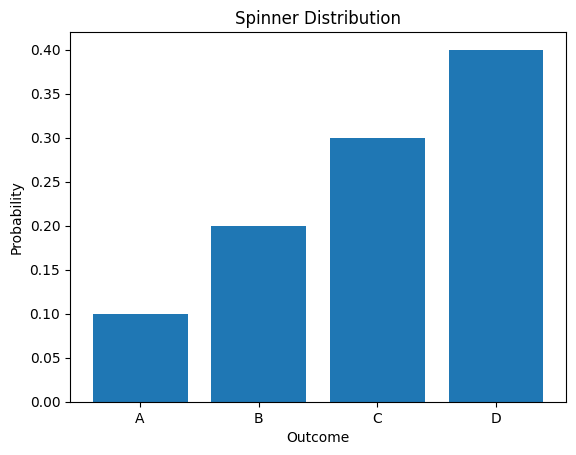

In [32]:
import pandas as pd
import matplotlib.pyplot as plt

spinner = pd.DataFrame({'Outcome': ['A', 'B', 'C', 'D'],
                   'Probability': [0.10, 0.20, 0.30, 0.40]})

print(spinner)

plt.bar(spinner['Outcome'], spinner['Probability'])
plt.title('Spinner Distribution')
plt.xlabel('Outcome')
plt.ylabel('Probability')
plt.show()

### 4.2 — Empirical Distributions (7 pts)
Use `rng.choice()` with the specified probabilities to simulate **20, 200, and 20,000 spins**. Calculate the empirical proportion of A, B, C, and D for each sample size and present the results in a DataFrame.

In [33]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(45)

outcomes = ['A', 'B', 'C', 'D']
probabilities = [0.10, 0.20, 0.30, 0.40]

results = []

for n in [20, 200, 20000]:
    spins = rng.choice(outcomes, size=n, p=probabilities)
    proportions = [np.mean(spins == outcome) for outcome in outcomes]
    results.append([n] + proportions)

empiracal_df = pd.DataFrame(results, columns=['Spins'] + outcomes)
print(empiracal_df)

   Spins        A       B       C        D
0     20  0.05000  0.0000  0.3500  0.60000
1    200  0.07000  0.2200  0.2850  0.42500
2  20000  0.10015  0.1992  0.2937  0.40695


### 4.3 — Law of Averages (4 pts)
Which empirical distribution tends to be closest to the theoretical distribution? Explain using the **law of averages**. Does this law mean that a small sample must closely match the theoretical distribution?

**Your answer:**

# Part 5 — Population Parameters and Sample Statistics (25 points)

Run the following cell to create a population of 4,000 customer wait times.

In [34]:
wait_times = np.round(rng.gamma(shape=2.5, scale=6.0, size=4000), 1)
population = pd.DataFrame({"Wait_Time": wait_times})
population.head()

,Wait_Time
0,30.2
1,12.6
2,2.3
3,15.1
4,13.0


### 5.1 — Population (5 pts)
Calculate the **population mean and median**. Are these quantities parameters or statistics? Explain.

In [35]:
population_mean = population['Wait_Time'].mean()
population_median = population['Wait_Time'].median()

print(f"Population Mean: {population_mean:.2f}")
print(f"Population Median: {population_median:.2f}")

Population Mean: 15.16
Population Median: 13.40


**Part 5.1 — Explanation**

The population mean and median are parameters because they are calculated using the entire population of 4,000 customer wait times. A parameter describes a characteristic of a population, while a statistic describes a characteristic of a sample taken from that population.

**Explanation:**

### 5.2 — Random Sample (10 pts)
Draw a simple random sample of **40 customers** and calculate its mean and median. Are these parameters or statistics? Explain.

In [36]:
rng = np.random.default_rng(45)
sample = population.sample(n=40, replace=False,random_state=45)
sample_mean = sample['Wait_Time'].mean()
sample_median = sample['Wait_Time'].median()

print(f"Sample Mean: {sample_mean:.2f}")
print(f"Sample Median: {sample_median:.2f}")

Sample Mean: 16.10
Sample Median: 12.30


**Explanation:**

### 5.3 — Sampling Variability (10 pts)
Run the sampling code several times. Do the sample statistics remain exactly the same? Does the population parameter change? Explain why.

**Your answer:****Part 5.2 — Explanation**

The mean and median calculated from the 40 randomly selected c are stats because they describe a sample rather than the entire population of 4,000 customers. These sample statistics can be used to estimate the population mean and median, but they may differ from the actual population parameters due to sampling variability.

# Part 6 — Empirical Distribution of a Statistic (25 points)

Continue using the customer wait-time population.

### 6.1 — Sampling Function (5 pts)
Write `random_sample_mean(sample_size)` to draw a random sample **without replacement** and return its mean.

In [37]:
def random_sample_mean(sample_size):
    sample = population.sample(n=sample_size, replace=False)
    sample_mean = sample['Wait_Time'].mean()
    return sample_mean

### 6.2 — Repeated Sampling (6 pts)
Take **2,000 random samples of size 40**. Store the 2,000 sample means in a NumPy array. Display the first 10 values and the array length.

In [38]:
import numpy as np

# Generate 2,000 sample means of size 40
sample_means_40 = np.array([random_sample_mean(40) for _ in range(2000)])

# Display requested information
print("First 10 sample means:", sample_means_40[:10])
print("Length of array:", len(sample_means_40))

First 10 sample means: [13.5775 14.0225 14.8975 14.25   14.0475 15.805  15.035  16.145  12.685
 15.99  ]
Length of array: 2000


### 6.3 — Visualization (6 pts)
Create a histogram of the 2,000 sample means. Add a **vertical dashed line** for the true population mean, plus an informative title and axis labels.

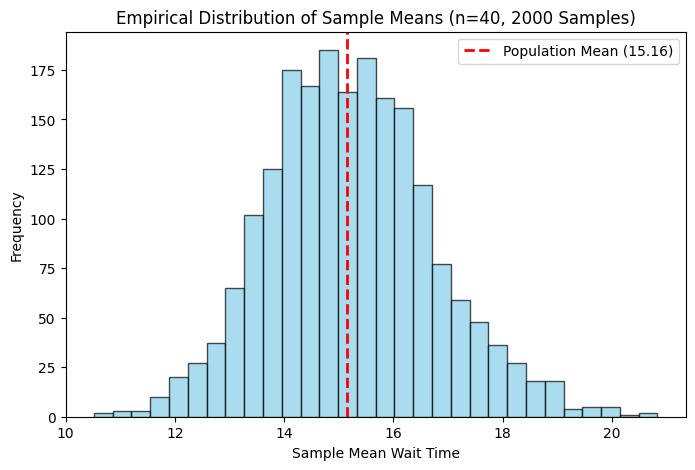

In [39]:
# Your plot

### 6.4 — Interpretation (8 pts)
Answer each in 1–2 sentences: Is the histogram a distribution of individual wait times or a distribution of a statistic? Explain.



**Write your answer here:**
**Part 6.4 — Interpretation**

The histogram represents the distribution of a statistic , not individual customer wait times. Each value in the histogram is the average waiting time calculated from a random sample of 40 customers, repeated 2,000 times.